<a href="https://colab.research.google.com/github/saichandanss2190/ITA0315-Mobile-Computing/blob/main/MC_Exp_16%2C17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

def fspl_db(d_km, f_mhz):
    """Free-space path loss in dB (d in km, f in MHz)."""
    return 20*np.log10(d_km) + 20*np.log10(f_mhz) + 32.44

Pt_dbm, Gt_db, Gr_db = 43.0, 15.0, 0.0
distances = [0.1, 0.5, 1, 2, 5, 10] # BS power, BS gain, MS gain, km

for f in (900, 1800):
    print(f"\nFrequency = {f} MHz")
    print(f"{'d (km)':>8}{'FSPL (dB)':>12}{'Pr (dBm)':>11}{'Pr (W)':>14}")
    for d in distances:
        L = fspl_db(d, f)
        Pr = Pt_dbm + Gt_db + Gr_db - L
        Pr_w = 10**(Pr/10) / 1000
        print(f"{d:8.1f}{L:12.2f}{Pr:11.2f}{Pr_w:14.3e}")


Frequency = 900 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       71.52     -13.52     4.441e-05
     0.5       85.50     -27.50     1.777e-06
     1.0       91.52     -33.52     4.441e-07
     2.0       97.55     -39.55     1.110e-07
     5.0      105.50     -47.50     1.777e-08
    10.0      111.52     -53.52     4.441e-09

Frequency = 1800 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       77.55     -19.55     1.110e-05
     0.5       91.52     -33.52     4.441e-07
     1.0       97.55     -39.55     1.110e-07
     2.0      103.57     -45.57     2.776e-08
     5.0      111.52     -53.52     4.441e-09
    10.0      117.55     -59.55     1.110e-09


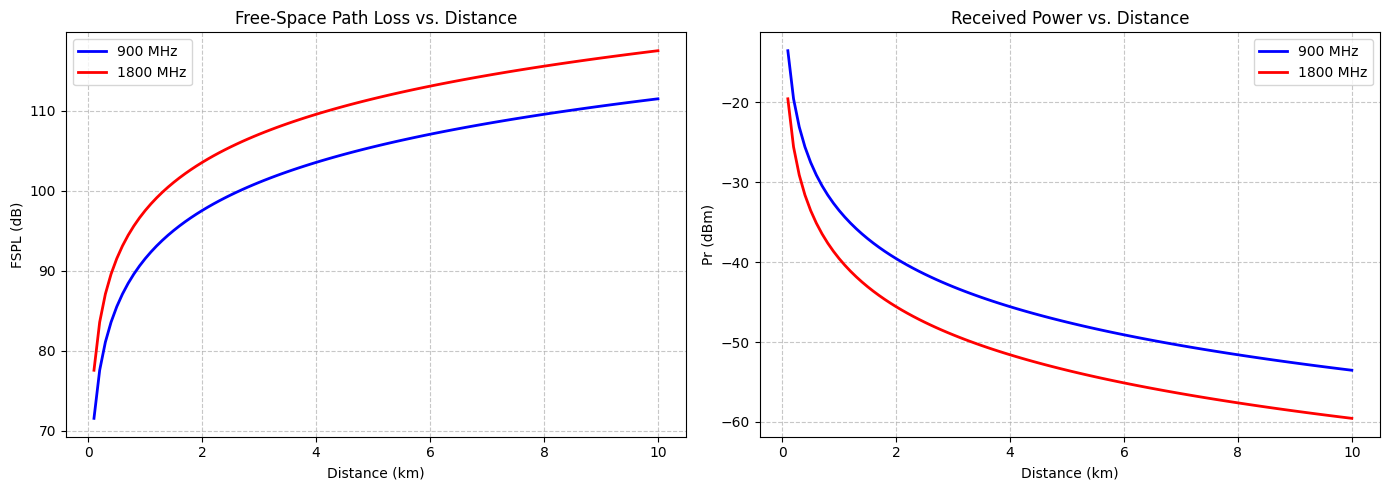

In [ ]:
import matplotlib.pyplot as plt

# Prepare data for plotting
distances_plot = np.linspace(0.1, 10, 100)

# Calculate path loss and received power
fspl_900 = fspl_db(distances_plot, 900)
fspl_1800 = fspl_db(distances_plot, 1800)

pr_900 = Pt_dbm + Gt_db + Gr_db - fspl_900
pr_1800 = Pt_dbm + Gt_db + Gr_db - fspl_1800

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Free-Space Path Loss
ax1.plot(distances_plot, fspl_900, label='900 MHz', color='blue', linewidth=2)
ax1.plot(distances_plot, fspl_1800, label='1800 MHz', color='red', linewidth=2)
ax1.set_title('Free-Space Path Loss vs. Distance')
ax1.set_xlabel('Distance (km)')
ax1.set_ylabel('FSPL (dB)')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

# Plot Received Power
ax2.plot(distances_plot, pr_900, label='900 MHz', color='blue', linewidth=2)
ax2.plot(distances_plot, pr_1800, label='1800 MHz', color='red', linewidth=2)
ax2.set_title('Received Power vs. Distance')
ax2.set_xlabel('Distance (km)')
ax2.set_ylabel('Pr (dBm)')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
import math

S = 420
M = 10
n = 4  # total duplex channels available, cluster replications, path-loss exponent

valid = sorted({i*i + i*j + j*j for i in range(0, 5) for j in range(0, 5)} - {0})[:8]

# Lists to store results for plotting
N_list = []
Q_list = []
k_list = []
C_list = []
si_db_list = []

print(f"{'N':>3}{'D/R':>8}{'ch/cell':>9}{'Capacity C':>12}{'S/I (dB)':>10}")
for N in valid:
    Q = math.sqrt(3*N)  # co-channel reuse ratio D/R
    k = S // N          # channels per cell
    C = M * k * N       # system capacity = M*k*N
    si = (Q**n) / 6     # 6 first-tier interferers
    si_db = 10 * math.log10(si)

    N_list.append(N)
    Q_list.append(Q)
    k_list.append(k)
    C_list.append(C)
    si_db_list.append(si_db)

    print(f"{N:>3}{Q:8.3f}{k:9d}{C:12d}{si_db:10.2f}")

req = 18.0  # AMPS requirement (dB)
for N in valid:
    if 10*math.log10((math.sqrt(3*N)**n)/6) >= req:
        print(f"\nSmallest cluster size meeting S/I >= {req} dB : N = {N}")
        break

  N     D/R  ch/cell  Capacity C  S/I (dB)
  1   1.732      420        4200      1.76
  3   3.000      140        4200     11.30
  4   3.464      105        4200     13.80
  7   4.583       60        4200     18.66
  9   5.196       46        4140     20.85
 12   6.000       35        4200     23.34
 13   6.245       32        4160     24.04
 16   6.928       26        4160     25.84

Smallest cluster size meeting S/I >= 18.0 dB : N = 7


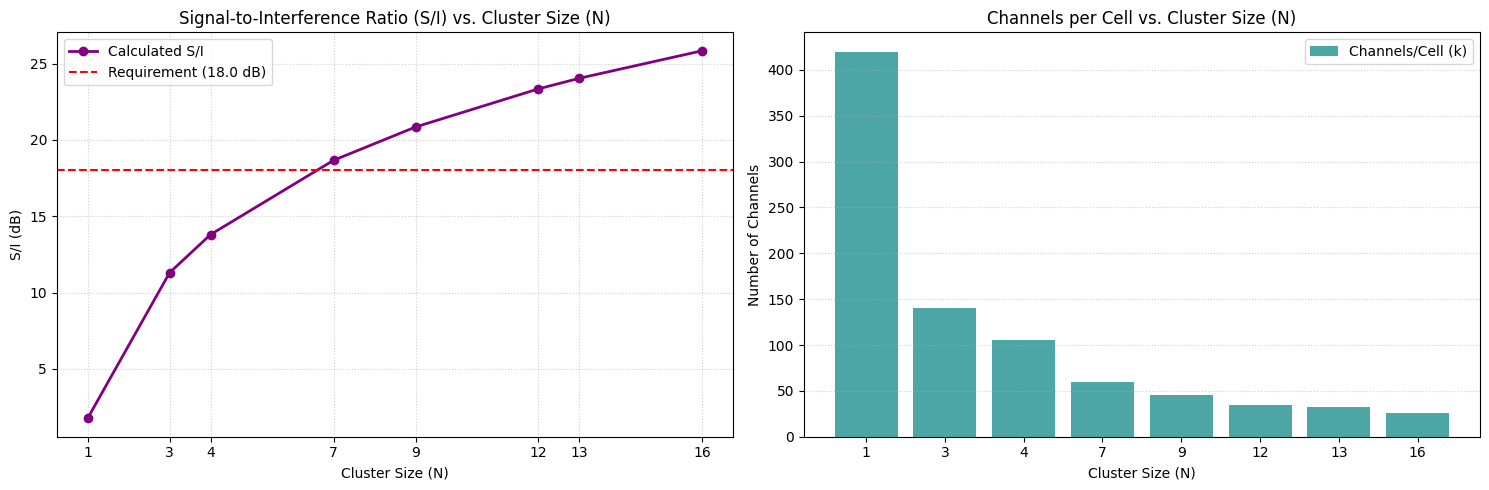

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Line Graph for S/I (dB) vs Cluster Size (N)
ax1.plot(N_list, si_db_list, marker='o', color='purple', linewidth=2, label='Calculated S/I')
ax1.axhline(y=req, color='red', linestyle='--', label=f'Requirement ({req} dB)')
ax1.set_title('Signal-to-Interference Ratio (S/I) vs. Cluster Size (N)')
ax1.set_xlabel('Cluster Size (N)')
ax1.set_ylabel('S/I (dB)')
ax1.set_xticks(N_list)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Plot 2: Bar Graph for Channels per Cell (k)
x = np.arange(len(N_list))
ax2.bar(x, k_list, color='teal', alpha=0.7, label='Channels/Cell (k)')
ax2.set_title('Channels per Cell vs. Cluster Size (N)')
ax2.set_xlabel('Cluster Size (N)')
ax2.set_ylabel('Number of Channels')
ax2.set_xticks(x)
ax2.set_xticklabels(N_list)
ax2.grid(axis='y', linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
def erlang_b(E, m):
    """Blocking probability using the recursive Erlang-B formula."""
    B = 1.0
    for k in range(1, m + 1):
        B = (E * B) / (k + E * B)
    return B

loads = [2, 5, 10, 20]
channels = [5, 10, 15, 20, 25, 30]

print("Blocking probability (%)")
print("E \\ m " + "".join(f"{m:>9}" for m in channels))
for E in loads:
    print(f"{E:>5} " + "".join(f"{100*erlang_b(E, m):9.3f}" for m in channels))

E, target = 10, 0.02
m = 1
while erlang_b(E, m) > target:
    m += 1
print(f"\nFor E = {E} Erlangs and GoS = {target*100:.0f}% -> channels required = {m}")

Blocking probability (%)
E \ m         5       10       15       20       25       30
    2     3.670    0.004    0.000    0.000    0.000    0.000
    5    28.487    1.838    0.016    0.000    0.000    0.000
   10    56.395   21.458    3.650    0.187    0.003    0.000
   20    76.436   53.796   33.000   15.889    5.022    0.846

For E = 10 Erlangs and GoS = 2% -> channels required = 17


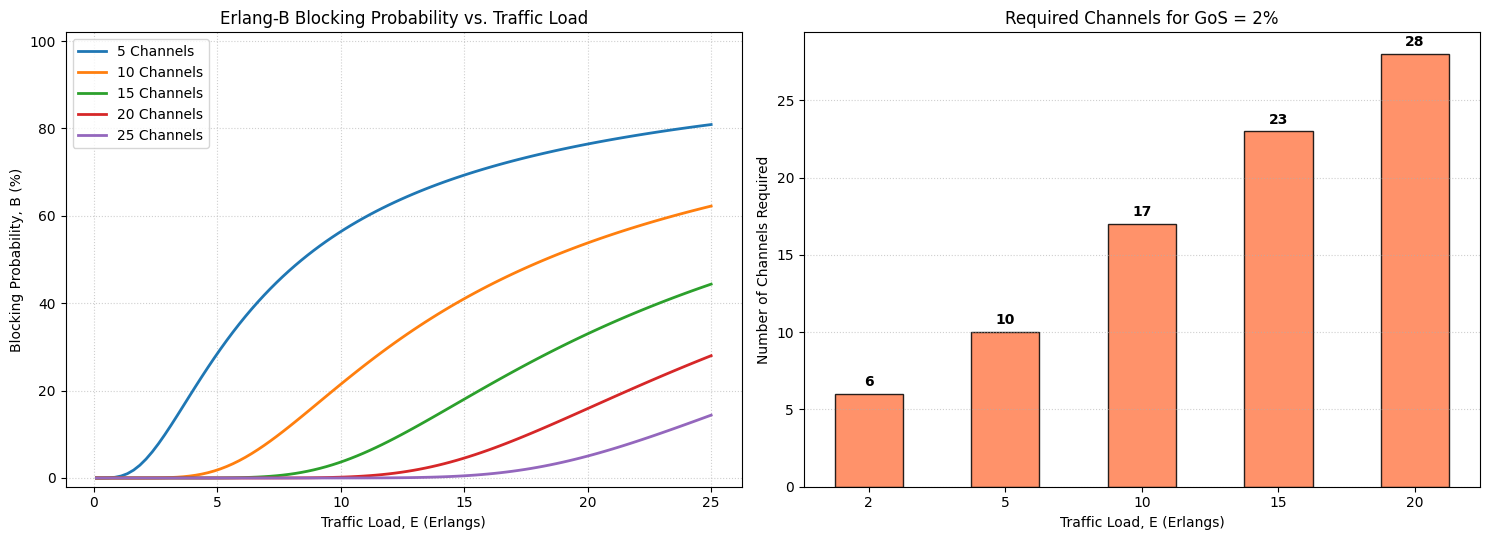

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting blocking probability curves
plot_loads = np.linspace(0.1, 25, 100)
plot_channels = [5, 10, 15, 20, 25]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Erlang-B Blocking Probability Curves
for m_val in plot_channels:
    b_probs = [erlang_b(E_val, m_val) * 100 for E_val in plot_loads]
    ax1.plot(plot_loads, b_probs, label=f'{m_val} Channels', linewidth=2)

ax1.set_title('Erlang-B Blocking Probability vs. Traffic Load')
ax1.set_xlabel('Traffic Load, E (Erlangs)')
ax1.set_ylabel('Blocking Probability, B (%)')
ax1.set_ylim(-2, 102)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Plot 2: Required Channels for 2% GoS across different loads
target_gos = 0.02
demo_loads = [2, 5, 10, 15, 20]
req_channels = []

for E_val in demo_loads:
    temp_m = 1
    while erlang_b(E_val, temp_m) > target_gos:
        temp_m += 1
    req_channels.append(temp_m)

x_pos = np.arange(len(demo_loads))
ax2.bar(x_pos, req_channels, color='coral', alpha=0.85, edgecolor='black', width=0.5)
ax2.set_title(f'Required Channels for GoS = {target_gos*100:.0f}%')
ax2.set_xlabel('Traffic Load, E (Erlangs)')
ax2.set_ylabel('Number of Channels Required')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(demo_loads)

# Add value labels on top of the bars
for i, val in enumerate(req_channels):
    ax2.text(i, val + 0.5, str(val), ha='center', fontweight='bold')

ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()